# IIR-0: the design spike for recursive stages in `rational`

> **This notebook runs Python designs (scipy, numpy and the spike's own `iir_design.py`), not the shipping C++.**
> Nothing here ships: `rational` has no IIR stage yet. The spike measures the IIR plan's open questions
> (the plan's section 5, item 1, its go/no-go list) on the designs its programs generate, and this notebook
> is its durable record and the first version of the demonstration the plan asks for (I11), on those
> designs. IIR-d's version will run the shipping C++ through the C ABI instead.

Everything the spike measured lives under `rational/tools/spikes/iir/`; its `README.md` states each result
with its provenance and the go/no-go verdicts. This notebook reads the committed outputs (`outputs/*.json`),
redraws them, and adds what only a picture shows. Re-execute from `rational/notebooks/` in the root
`requirements.lock` environment (plus `mpmath` for the accuracy table's generator, which this notebook does
not run):

```sh
jupyter nbconvert --to notebook --execute --inplace iir_spike.ipynb
```

Conventions: a profile is (A dB, p) with p the passband edge over the chain's lowest rate (`design.h`); a
stage at design divisor d has its passband at p / d of its own lower rate and its stopband mirrored about its
own low Nyquist (the plan's I13). Frequencies on the plots are fractions of the rate named on each axis.

In [1]:
import json, math, pathlib, sys, tempfile
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

HERE = pathlib.Path.cwd()
SPIKE = HERE.parent / "tools" / "spikes" / "iir"
sys.path.insert(0, str(SPIKE / "python"))
import figure_digest  # prints a data digest per figure (A/B gates)
figure_digest.install()
import iir_design as d

OUT = SPIKE / "outputs"
designs = json.loads((OUT / "designs.json").read_text())
tables = json.loads((OUT / "tables.json").read_text())
fourpath = json.loads((OUT / "fourpath.json").read_text()) if (OUT / "fourpath.json").exists() else {}
targets = json.loads((OUT / "targets.json").read_text()) if (OUT / "targets.json").exists() else {}
plt.rcParams.update({"figure.dpi": 80, "font.size": 9})

def two_path(prof, kind, div):
    e = designs["profiles"][prof][kind][str(div)]
    if kind == "nonlinear":
        return d.TwoPath("nonlinear", a0=np.array(e["a0"]), a1=np.array(e["a1"]))
    return d.TwoPath("near_linear", K=e["K"], den=np.array(e["den"]))

def fir_halfband(prof, m):
    # rational's FIR half-band (tap::dsp::design_nyquist through design.h), re-derived in numpy as
    # design_spike.ipynb does: Kaiser-windowed sinc, length 4m - 1, centre 1/2 at the high rate's gain 1
    A, p = d.PROFILES[prof]
    beta = 0.1102 * (A - 8.7)
    n = 4 * m - 1; c = (n - 1) // 2; i = np.arange(n); u = (i - c) / c
    w = np.i0(beta * np.sqrt(np.maximum(0, 1 - u * u))) / np.i0(beta)
    h = np.sinc((i - c) / 2) / 2 * w
    h[c] = 0.5; h[(i != c) & ((i - c) % 2 == 0)] = 0.0
    return h / h.sum()
print("profiles:", {k: v for k, v in d.PROFILES.items()})

profiles: {'super_economy': (70.0, 0.3333333333333333), 'economy': (70.0, 0.375), 'balanced': (70.0, 0.3958333333333333), 'transparent': (120.0, 0.4166666666666667)}


## 1. The designs: sections per profile, variant and divisor

The nonlinear variant is the closed-form elliptic half-band; the near-linear variant puts a pure delay
w^-K on one path and an order-N allpass on the other, designed by minimax (`iir_design.nearlinear_design`).
Both meet -(A + 1 dB) on the 16384-point grid, rational's design margin. MACs are per decimated output
frame per channel (the allpass coefficients; the near-linear delay path is free).

In [2]:
rows = []
for prof in d.PROFILE_ORDER:
    for div in d.DIVISORS:
        nl = designs["profiles"][prof]["nonlinear"][str(div)]
        nr = designs["profiles"][prof]["near_linear"][str(div)]
        rows.append((prof, div, nl["order"], (nl["order"] - 1) // 2, nl["stopband_db"], nr["N"], nr["K"], nr["stopband_db"]))
print(f"{'profile':14s} {'d':>2s} | {'nonlinear':>9s} {'MACs':>4s} {'stop':>7s} | {'near-lin N':>10s} {'K':>3s} {'stop':>7s}")
for r in rows:
    print(f"{r[0]:14s} {r[1]:2d} | {'N' + str(r[2]):>9s} {r[3]:4d} {r[4]:7.1f} | {r[5]:10d} {r[6]:3d} {r[7]:7.1f}")

profile         d | nonlinear MACs    stop | near-lin N   K    stop
super_economy   1 |        N9    4   -90.0 |          5   5   -75.5
super_economy   2 |        N5    2   -81.2 |          2   2   -73.9
super_economy   4 |        N5    2  -112.1 |          2   2  -104.8
super_economy   8 |        N3    1   -83.0 |          1   1   -83.0
economy         1 |        N9    4   -77.6 |          7   7   -77.5
economy         2 |        N5    2   -75.8 |          3   3   -92.2
economy         4 |        N5    2  -107.0 |          2   2   -99.6
economy         8 |        N3    1   -80.0 |          1   1   -80.0
balanced        1 |        N9    4   -71.3 |          8   8   -74.6
balanced        2 |        N5    2   -73.3 |          3   3   -88.7
balanced        4 |        N5    2  -104.6 |          2   2   -97.2
balanced        8 |        N3    1   -78.6 |          1   1   -78.6
transparent     1 |       N17    8  -127.9 |         19  19  -121.2
transparent     2 |        N9    4  -132.5 |    

[ figure ] digest d7b48f2e0d779518 (12 arrays)


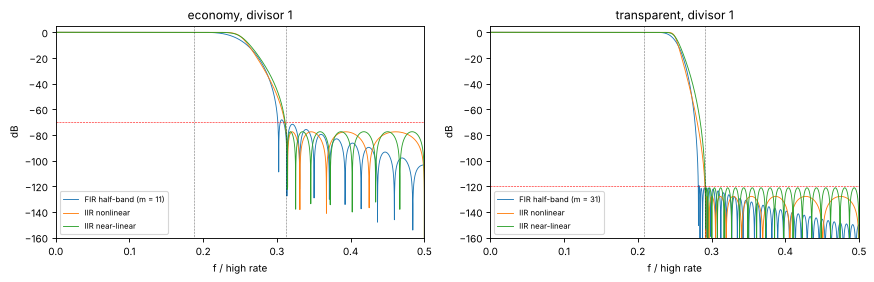

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
f = np.linspace(0, 0.5, 8192)
for prof, ax in zip(("economy", "transparent"), axes):
    A, p = d.PROFILES[prof]
    m = {"economy": 11, "transparent": 31}[prof]
    h = fir_halfband(prof, m)
    _, Hf = signal.freqz(h, worN=2 * np.pi * f)
    ax.plot(f, d.db(Hf), lw=0.8, label=f"FIR half-band (m = {m})")
    ax.plot(f, d.db(two_path(prof, "nonlinear", 1).response(f)), lw=0.8, label="IIR nonlinear")
    ax.plot(f, d.db(two_path(prof, "near_linear", 1).response(f)), lw=0.8, label="IIR near-linear")
    ax.axvline(p / 2, color="k", lw=0.5, ls=":"); ax.axvline(0.5 - p / 2, color="k", lw=0.5, ls=":")
    ax.axhline(-A, color="r", lw=0.5, ls="--")
    ax.set_ylim(-160, 5); ax.set_xlim(0, 0.5); ax.set_title(f"{prof}, divisor 1"); ax.set_xlabel("f / high rate")
    ax.set_ylabel("dB"); ax.legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

## 2. Group delay, and the near-linear identity

For the near-linear structure the stopband at the mirror of a passband frequency is exactly |sin(eps/2)|,
where eps is the allpass path's phase error against the delay path, and the passband phase error is eps/2.
So the attained stopband bounds the passband phase error by asin of it, whatever the weighting; at
exactly 70 dB that is 0.0181 degrees. The right panel draws both sides of the identity for `economy`.

[ figure ] digest a2b3df639d4e81d5 (6 arrays)


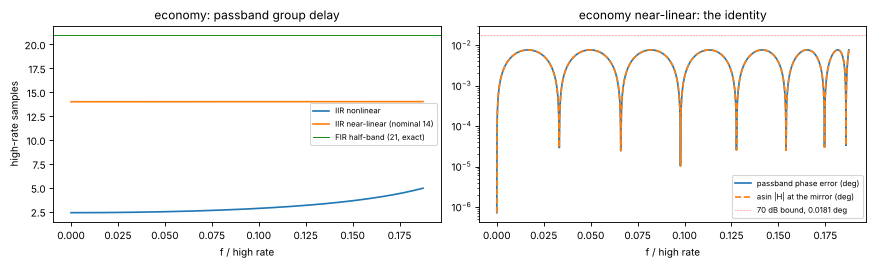

largest |phase error - asin(mirror)| (deg): 1.5331561974835095e-13


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
prof = "economy"; A, p = d.PROFILES[prof]
fp = p / 2
f = np.linspace(1e-6, fp, 2000)
nl, nr = two_path(prof, "nonlinear", 1), two_path(prof, "near_linear", 1)
axes[0].plot(f, nl.group_delay(f), label="IIR nonlinear")
axes[0].plot(f, nr.group_delay(f), label=f"IIR near-linear (nominal {2 * nr.K})")
axes[0].axhline(21, color="g", lw=0.8, label="FIR half-band (21, exact)")
axes[0].set_xlabel("f / high rate"); axes[0].set_ylabel("high-rate samples"); axes[0].legend(fontsize=7)
axes[0].set_title("economy: passband group delay")
pe = np.degrees(np.abs(d.nearlinear_phase_error(nr.den, nr.K, 4 * np.pi * f) / 2))
mirror = np.degrees(np.arcsin(np.abs(nr.response(0.5 - f))))
axes[1].semilogy(f, pe, label="passband phase error (deg)")
axes[1].semilogy(f, mirror, "--", label="asin |H| at the mirror (deg)")
axes[1].axhline(np.degrees(math.asin(10 ** (-70 / 20))), color="r", lw=0.5, ls=":", label="70 dB bound, 0.0181 deg")
axes[1].set_xlabel("f / high rate"); axes[1].legend(fontsize=7); axes[1].set_title("economy near-linear: the identity")
plt.tight_layout(); plt.show()
print("largest |phase error - asin(mirror)| (deg):", float(np.max(np.abs(pe - mirror))))

## 3. Round trips

Down through the relaxed stages and up through the same ones; a half-band's decimator and interpolator
share one H(z), so their phase errors add. The plan's target (question 5) is 0.57 degrees (-40 dB); the FIR
round trip is pinned at -60 dB.

profile        trip  phase deg  residual dB
super_economy    x2     0.0193        -69.5
super_economy    x4     0.0424        -62.6
super_economy    x8     0.0431        -62.5
super_economy   x16     0.0512        -61.0
economy          x2     0.0153        -71.5
economy          x4     0.0181        -70.0
economy          x8     0.0193        -69.4
economy         x16     0.0308        -65.4
balanced         x2     0.0212        -68.6
balanced         x4     0.0254        -67.1
balanced         x8     0.0270        -66.5
balanced        x16     0.0405        -63.0
transparent      x2     0.0001       -115.2
transparent      x4     0.0002       -111.5
transparent      x8     0.0002       -109.5
transparent     x16     0.0003       -107.1
[ figure ] digest c8fea04518100fe2 (6 arrays)


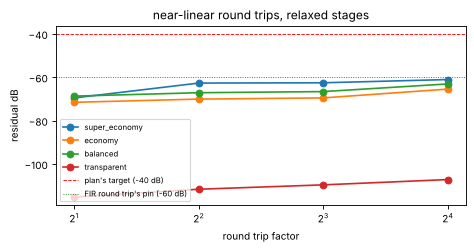

In [5]:
print(f"{'profile':14s} {'trip':>4s} {'phase deg':>10s} {'residual dB':>12s}")
for k, v in tables["round_trip"].items():
    prof, trip = k.split("/")
    print(f"{prof:14s} {trip:>4s} {v['max_phase_deg']:10.4f} {v['residual_db']:12.1f}")
fig, ax = plt.subplots(figsize=(6, 3.2))
for prof in d.PROFILE_ORDER:
    ax.plot([2, 4, 8, 16], [tables["round_trip"][f"{prof}/x{n}"]["residual_db"] for n in (2, 4, 8, 16)], "o-", label=prof)
ax.axhline(-40, color="r", ls="--", lw=0.8, label="plan's target (-40 dB)")
ax.axhline(-60, color="g", ls=":", lw=0.8, label="FIR round trip's pin (-60 dB)")
ax.set_xscale("log", base=2); ax.set_xlabel("round trip factor"); ax.set_ylabel("residual dB"); ax.legend(fontsize=7)
ax.set_title("near-linear round trips, relaxed stages"); plt.tight_layout(); plt.show()

## 4. The guard band filter, both forms

At the low rate, flat within 0.01 dB peak to peak to the passband edge, A dB from the stopband edge that
follows from the order. The odd-order Chebyshev II and the even-length type II FIR both put a zero at the
low Nyquist.

[ figure ] digest 749c4d13cb2d5137 (6 arrays)


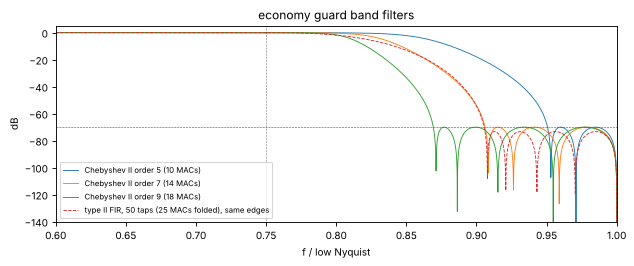

the order rule (worst combined alias <= -A/2): {'super_economy': 5, 'economy': 7, 'balanced': 7, 'transparent': 7}


In [6]:
prof = "economy"; A, p = d.PROFILES[prof]
fig, ax = plt.subplots(figsize=(8, 3.4))
f = np.linspace(0, 0.5, 8192)
for order in (5, 7, 9):
    fs, zpk = d.cheby2_design(p, order, A)
    _, G = signal.freqz_zpk(*zpk, worN=2 * np.pi * f)
    ax.plot(f / 0.5, d.db(G), lw=0.8, label=f"Chebyshev II order {order} ({d.cheby2_macs(order)} MACs)")
fs7 = d.cheby2_stopband_edge(p, 7, A)
n7, h7, _, _ = d.typeii_min_length(p, fs7, A)
_, Gf = signal.freqz(h7, worN=2 * np.pi * f)
ax.plot(f / 0.5, d.db(Gf), lw=0.8, ls="--", label=f"type II FIR, {n7} taps ({n7 // 2} MACs folded), same edges")
ax.axvline(p / 0.5, color="k", lw=0.5, ls=":"); ax.axhline(-A, color="r", lw=0.5, ls="--")
ax.set_ylim(-140, 5); ax.set_xlim(0.6, 1.0); ax.set_xlabel("f / low Nyquist"); ax.set_ylabel("dB")
ax.set_title("economy guard band filters"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()
print("the order rule (worst combined alias <= -A/2):", {k: v["order"] for k, v in tables["guard_rule"].items()})

## 5. The demonstration (I11, first version, on scipy designs)

A logarithmic sine sweep from 20 Hz to just below the input Nyquist at -6 dBFS, 48 kHz in, through a
decimator by 2 to 24 kHz at `economy` (passband to 9 kHz, guard band 9 to 12 kHz). Each configuration runs
the **transfer function** of the design in direct form (`scipy.signal.lfilter`) and keeps every second
sample; the two are the same filter as the polyphase stage, which is what IIR-d's notebook will run through
the C ABI. Spectrograms on one fixed scale, 0 to -140 dB, with the passband edge (white), the guard band
filter's stopband edge (cyan) and the low Nyquist (top) drawn.

In [7]:
FS = 48000.0
dur = 3.0
t = np.arange(int(FS * dur)) / FS
f0, f1 = 20.0, 0.995 * FS / 2
sweep = 0.5 * np.sin(2 * np.pi * f0 * dur / np.log(f1 / f0) * (np.exp(t / dur * np.log(f1 / f0)) - 1))
inst = f0 * np.exp(t / dur * np.log(f1 / f0))  # its instantaneous frequency

prof = "economy"; A, p = d.PROFILES[prof]
def tf_two_path(hb):
    # the half-band's high-rate transfer function H(z) = 1/2 [A0(z^2) + z^-1 A1(z^2)] as polynomials
    up = lambda c: np.ravel(np.column_stack([c, np.zeros_like(c)]))[:-1]
    if hb.kind == "nonlinear":
        def ap(coefs):
            num, den = np.array([1.0]), np.array([1.0])
            for a in coefs:
                num = np.convolve(num, [a, 0, 1]); den = np.convolve(den, [1, 0, a])
            return num, den
        n0, d0 = ap(hb.a0); n1, d1 = ap(hb.a1)
        u, v = np.convolve(n0, d1), np.r_[0, np.convolve(n1, d0)]
        n = max(len(u), len(v))
        return 0.5 * (np.pad(u, (0, n - len(u))) + np.pad(v, (0, n - len(v)))), np.convolve(d0, d1)
    den = up(hb.den); num = up(hb.den[::-1])
    t1 = np.zeros(2 * hb.K + len(den)); t1[2 * hb.K:2 * hb.K + len(den)] = den
    t2 = np.zeros_like(t1); t2[1:1 + len(num)] = num
    return 0.5 * (t1 + t2), den

fir = fir_halfband(prof, 11)
hb_nl = tf_two_path(two_path(prof, "nonlinear", 1))
hb_nr = tf_two_path(two_path(prof, "near_linear", 1))
order = tables["guard_rule"][prof]["order"]
fs_g, zpk_g = d.cheby2_design(p, order, A)
sos_g = signal.zpk2sos(*zpk_g)
_, h_lin, _, _ = d.typeii_min_length(p, fs_g, A)
# the same order before the decimator (at 48 kHz) and the order that matches the after-filter there
sos_pre_same = signal.zpk2sos(*signal.cheby2(order, A, 2 * d.cheby2_stopband_edge(p / 2, order, A), output="zpk"))
n_match, _ = signal.cheb2ord(p / 2 * 2, fs_g / 2 * 2, 0.01, A); n_match += 1 - n_match % 2
sos_pre_match = signal.zpk2sos(*signal.cheby2(n_match, A, fs_g, output="zpk"))

def down(x, hb=None, guard=None, pre=None):
    y = x
    if pre is not None: y = signal.sosfilt(pre, y)
    y = signal.lfilter(*hb, y) if isinstance(hb, tuple) else signal.lfilter(hb, [1.0], y)
    y = y[::2]
    if guard == "cheb": y = signal.sosfilt(sos_g, y)
    if guard == "linear": y = signal.lfilter(h_lin, [1.0], y)
    return y

configs = {
    "FIR alone": down(sweep, fir), "FIR + Chebyshev II": down(sweep, fir, "cheb"), "FIR + type II": down(sweep, fir, "linear"),
    "IIR nonlinear alone": down(sweep, hb_nl), "IIR nonlinear + Chebyshev II": down(sweep, hb_nl, "cheb"),
    "IIR nonlinear + type II": down(sweep, hb_nl, "linear"),
    "IIR near-linear alone": down(sweep, hb_nr), "IIR near-linear + Chebyshev II": down(sweep, hb_nr, "cheb"),
    "IIR near-linear + type II": down(sweep, hb_nr, "linear"),
    f"IIR nonlinear, order {order} BEFORE": down(sweep, hb_nl, pre=sos_pre_same),
    f"IIR nonlinear, order {n_match} BEFORE": down(sweep, hb_nl, pre=sos_pre_match),
}
print("guard order", order, "| stop edge", round(fs_g * 24000), "Hz | type II taps", len(h_lin), "| matching order before:", n_match)

guard order 7 | stop edge 10873 Hz | type II taps 50 | matching order before: 17


[ figure ] digest 35160d9b80287c2c (47 arrays)


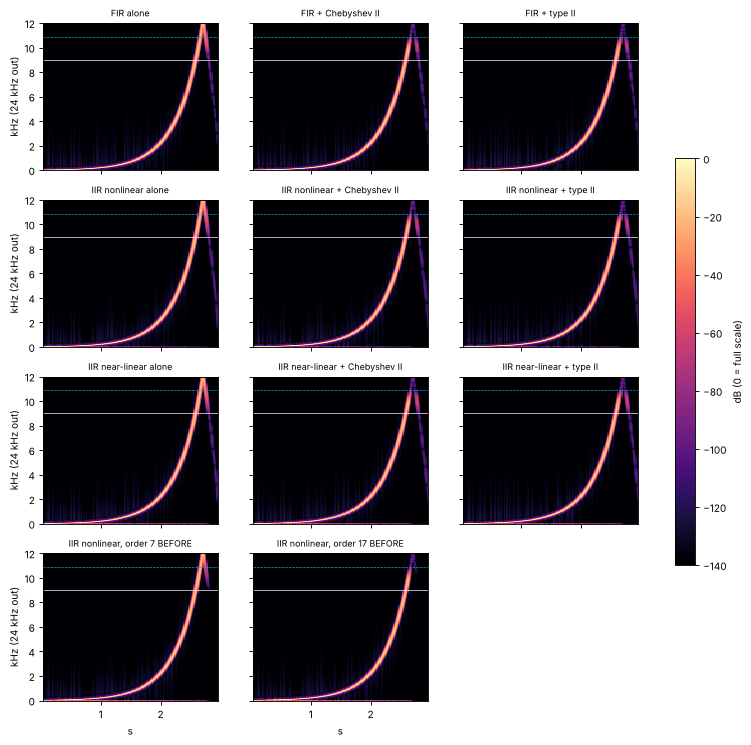

In [8]:
def spec(y, fs=24000.0):
    f, tt, S = signal.spectrogram(y, fs=fs, window="blackmanharris", nperseg=2048, noverlap=1536, scaling="spectrum")
    # 0 dB = a full-scale sine (amplitude 1); the sweep is at -6 dBFS
    return f, tt, 10 * np.log10(np.maximum(S * 2, 1e-30))

fig, axes = plt.subplots(4, 3, figsize=(12, 11), sharex=True, sharey=True)
for ax, (name, y) in zip(axes.ravel(), configs.items()):
    f, tt, S = spec(y)
    im = ax.pcolormesh(tt, f / 1000, S, vmin=-140, vmax=0, shading="auto", cmap="magma", rasterized=True)
    ax.axhline(p * 24, color="w", lw=0.6); ax.axhline(fs_g * 24, color="c", lw=0.6, ls="--")
    ax.set_title(name, fontsize=8)
for ax in axes.ravel()[len(configs):]: ax.axis("off")
for ax in axes[:, 0]: ax.set_ylabel("kHz (24 kHz out)")
for ax in axes[-1, :]: ax.set_xlabel("s")
fig.colorbar(im, ax=axes, shrink=0.6, label="dB (0 = full scale)")
plt.show()

The worst alias of each configuration, measured on the sweep. A log sweep moves through hundreds of bins in
one analysis frame, so a single bin under-reads it; instead, in every frame where the input is above the
output Nyquist, the power summed over the band the alias crosses during that frame, against the input's
power summed over the band it crosses in the same span (both 21 ms Blackman-Harris frames, so the scalings
cancel), by where the alias lands.

In [9]:
fi_spec = signal.spectrogram(sweep, fs=48000.0, window="blackmanharris", nperseg=1024, noverlap=768, scaling="spectrum")
def alias_table(y):
    f, tt, S = signal.spectrogram(y, fs=24000.0, window="blackmanharris", nperseg=512, noverlap=384, scaling="spectrum")
    fin_f, fin_t, Sin = fi_spec
    df = f[1] - f[0]
    half = 256 / 24000.0
    pb, gb, above = [], [], []
    for j, tj in enumerate(tt):
        fa, fb = np.interp([tj - half, tj + half], t, inst)
        if fa <= 12000 or fb >= 23900: continue
        lo, hi = 24000 - fb - 3 * df, 24000 - fa + 3 * df
        sel = (f >= lo) & (f <= hi)
        ref = (fin_f >= fa - 3 * df) & (fin_f <= fb + 3 * df)
        k = min(j, Sin.shape[1] - 1)
        lvl = 10 * np.log10(S[sel, j].sum() / Sin[ref, k].sum())
        mid = 24000 - 0.5 * (fa + fb)
        (pb if mid <= p * 24000 else gb if mid < fs_g * 24000 else above).append(lvl)
    return [max(v) if v else float("nan") for v in (pb, gb, above)]

print(f"{'configuration':38s} {'passband':>9s} {'guard band':>11s} {'above stop':>11s}  (dB re the input)")
for name, y in configs.items():
    a = alias_table(y)
    print(f"{name:38s} {a[0]:9.1f} {a[1]:11.1f} {a[2]:11.1f}")

configuration                           passband  guard band  above stop  (dB re the input)
FIR alone                                  -72.1       -18.5        -8.6
FIR + Chebyshev II                         -72.1       -44.9       -79.4
FIR + type II                              -72.1       -47.0       -85.0
IIR nonlinear alone                        -77.6       -20.0        -6.6
IIR nonlinear + Chebyshev II               -77.6       -44.0       -77.3
IIR nonlinear + type II                    -76.5       -46.3       -82.8
IIR near-linear alone                      -77.2       -17.0        -5.9
IIR near-linear + Chebyshev II             -76.6       -39.7       -76.7
IIR near-linear + type II                  -74.4       -42.0       -82.2
IIR nonlinear, order 7 BEFORE             -112.7       -32.0       -11.9
IIR nonlinear, order 17 BEFORE            -147.7       -90.2       -78.5


[ figure ] digest 1c157e412b8471c3 (24 arrays)


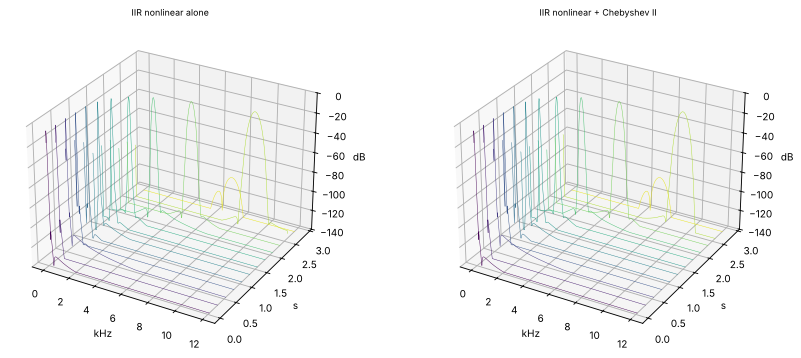

In [10]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
fig = plt.figure(figsize=(11, 4.6))
for i, name in enumerate(("IIR nonlinear alone", "IIR nonlinear + Chebyshev II")):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    f, tt, S = spec(configs[name])
    for j in range(0, len(tt), 12):
        ax.plot(f / 1000, np.full_like(f, tt[j]), np.maximum(S[:, j], -140), lw=0.4, color=plt.cm.viridis(j / len(tt)))
    ax.set_zlim(-140, 0); ax.set_xlabel("kHz"); ax.set_ylabel("s"); ax.set_zlabel("dB"); ax.set_title(name, fontsize=8)
    ax.view_init(elev=28, azim=-60)
plt.tight_layout(); plt.show()

**The interpolating mirror.** A 24 kHz sweep through an interpolator by 2 to 48 kHz: without the guard band
filter, the input's content between the passband edge and the low Nyquist images into the half-band's
transition band; with it (before the interpolator), the image is gone from the filter's stopband edge up.

[ figure ] digest 5158eb9a5968b1eb (11 arrays)


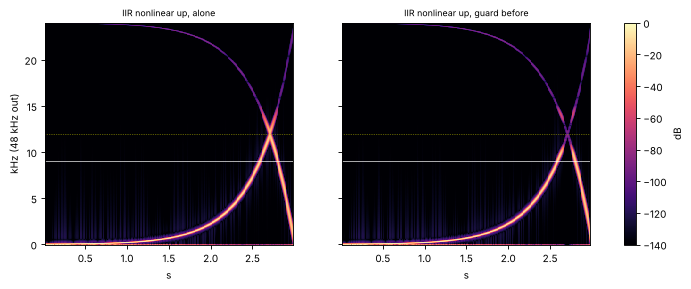

In [11]:
sweep_lo = sweep[::2]
def up2(x, hb, guard=False):
    y = signal.sosfilt(sos_g, x) if guard else x
    z = np.zeros(2 * len(y)); z[::2] = 2 * y
    return signal.lfilter(*hb, z)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, y) in zip(axes, (("IIR nonlinear up, alone", up2(sweep_lo, hb_nl)), ("IIR nonlinear up, guard before", up2(sweep_lo, hb_nl, True)))):
    f, tt, S = spec(y, 48000.0)
    im = ax.pcolormesh(tt, f / 1000, S, vmin=-140, vmax=0, shading="auto", cmap="magma", rasterized=True)
    ax.axhline(p * 24, color="w", lw=0.6); ax.axhline(12, color="y", lw=0.6, ls=":"); ax.set_title(name, fontsize=8)
    ax.set_xlabel("s")
axes[0].set_ylabel("kHz (48 kHz out)"); fig.colorbar(im, ax=axes, label="dB"); plt.show()

[ figure ] digest 923e3d769b1b4c37 (5 arrays)


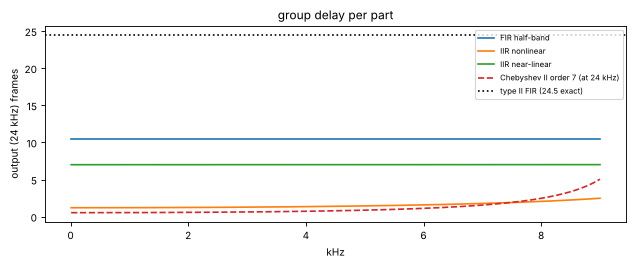

listening clips written outside the tree, to /tmp/iir_spike_clips


In [12]:
fig, ax = plt.subplots(figsize=(8, 3.4))
fg = np.linspace(10, p * 24000, 600)
w = 2 * np.pi * fg / 48000
for name, (b, a) in (("FIR half-band", (fir, [1.0])), ("IIR nonlinear", hb_nl), ("IIR near-linear", hb_nr)):
    _, g = signal.group_delay((b, a), w=w)
    ax.plot(fg / 1000, g / 2, label=name)
_, gg = signal.group_delay(signal.zpk2tf(*zpk_g), w=2 * np.pi * fg / 24000)
ax.plot(fg / 1000, gg, ls="--", label=f"Chebyshev II order {order} (at 24 kHz)")
ax.axhline((len(h_lin) - 1) / 2, ls=":", color="k", label=f"type II FIR ({(len(h_lin) - 1) / 2} exact)")
ax.set_xlabel("kHz"); ax.set_ylabel("output (24 kHz) frames"); ax.legend(fontsize=7); ax.set_title("group delay per part")
plt.tight_layout(); plt.show()
out = pathlib.Path(tempfile.gettempdir()) / "iir_spike_clips"
out.mkdir(exist_ok=True)
for name in ("FIR alone", "IIR nonlinear alone", "IIR nonlinear + Chebyshev II"):
    y = configs[name]
    wavfile.write(out / (name.replace(" ", "_").replace("+", "and") + ".wav"), 24000, (y / max(1e-9, np.abs(y).max()) * 0.5).astype(np.float32))
print("listening clips written outside the tree, to", out)

## 6. The four-path stage (I12)

One four-path stage against the pair of half-bands it would replace, on the bands that fold onto the
passband (`python/fourpath.py`). The bar: more than 10 % fewer MACs (or instructions).

In [13]:
if fourpath:
    print(f"{'placement':22s} {'pair MACs':>9s} {'tie S':>6s} {'found S':>8s}  best stopband per S (dB)")
    for k, v in fourpath.items():
        found = v["found_sections"]
        per = ", ".join(f"{s}:{e[0]:.0f}" for s, e in v["per_sections"].items())
        print(f"{k:22s} {v['pair_macs']:9d} {v['tie_sections']:6d} {str(found):>8s}  {per}")
else:
    print("outputs/fourpath.json not found: run python/fourpath.py")

placement              pair MACs  tie S  found S  best stopband per S (dB)
super_economy/D1               8      8     None  1:-12, 2:-19, 3:-32, 4:-35, 5:-43, 6:-56, 7:-59, 8:-69
super_economy/D2              12      6        6  1:-18, 2:-25, 3:-52, 4:-55, 5:-64, 6:-90
super_economy/D4              16      4        4  1:-24, 2:-31, 3:-71, 4:-73
economy/D1                     8      8     None  1:-11, 2:-18, 3:-28, 4:-31, 5:-39, 6:-49, 7:-52, 8:-62
economy/D2                    12      6        6  1:-17, 2:-24, 3:-49, 4:-52, 5:-60, 6:-84
economy/D4                    16      4     None  1:-23, 2:-30, 3:-68, 4:-70
balanced/D1                    8      8     None  1:-11, 2:-17, 3:-26, 4:-29, 5:-37, 6:-45, 7:-49, 8:-58
balanced/D2                   12      6        6  1:-16, 2:-24, 3:-47, 4:-50, 5:-59, 6:-82
balanced/D4                   16      4     None  1:-22, 2:-30, 3:-66, 4:-69
transparent/D1                16     16     None  1:-10, 2:-17, 3:-24, 4:-27, 5:-35, 6:-42, 7:-46, 8:-54, 

## 7. Instructions on the targets

`icount/run_targets.py`: each workload under QEMU with the family's counting plugin, per 32-frame mono block
(Hexagon counts packets), `economy` unless named, today's FIR `basic_stage` in the same harness for scale;
the cascades are I12's comparison (`python/gen_cascades.py`). The table is `outputs/targets.md`.

In [14]:
tmd = OUT / "targets.md"
print(tmd.read_text() if tmd.exists() else "outputs/targets.md not found: run icount/run_targets.py")

# IIR-0: instructions per 32-output-frame mono block (generated by icount/run_targets.py)

Hexagon counts packets. `economy` unless named.

| workload | m4 | m4f | m33 | m55 | hexagon |
|---|---:|---:|---:|---:|---:|
| IIR down 2, float states | 21,632 | 1,038 | 1,038 | 1,008 | 197 |
| IIR down 2, double states | 29,402 | 29,401 | 29,401 | 1,010 | 5,642 |
| IIR down 2, Q15 (Q3.28, magnitude truncation) | 2,146 | 2,146 | 2,279 | 2,377 | 704 |
| IIR down 2, Q15 (Q3.28, floor) | 1,601 | 1,602 | 1,634 | 1,898 | 452 |
| IIR down 2, Q31 (Q3.60, magnitude truncation) | 5,146 | 5,178 | 5,178 | 5,597 | 1,467 |
| IIR down 2, Q31 (Q3.60, floor) | 4,410 | 4,445 | 4,442 | 4,539 | 892 |
| IIR near-linear down 2, float | 36,734 | 2,127 | 2,161 | 2,263 | 620 |
| IIR near-linear down 2, Q15 | 3,365 | 3,495 | 3,367 | 3,567 | 1,537 |
| IIR up 2, float | 9,565 | 507 | 507 | 493 | 88 |
| IIR up 2, Q15 (magnitude truncation) | 1,139 | 1,172 | 1,186 | 1,237 | 341 |
| FIR down 2, float (today's basic_stage) |